In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os
import random
from datetime import datetime
from pathlib import Path

In [2]:
data_dir = '/data/icecores/Output/AL/DEN/DEN13A/'



target_dataids = {"HSIUM-457", "HSIUM-470", "HSIUM-478", "HSIUM-486"}  # manually define DataIDs you want
latest_csv_per_dataid = {}

# Go through each core dir
for core_dir in sorted(os.listdir(data_dir)):
    core_path = os.path.join(data_dir, core_dir)
    if not os.path.isdir(core_path):
        continue

    # Go through each timestamped subdir
    timestamp_dirs = sorted([
        os.path.join(core_path, d)
        for d in os.listdir(core_path)
        if os.path.isdir(os.path.join(core_path, d))
    ])

    for ts_dir in timestamp_dirs:
        readme_path = os.path.join(ts_dir, "README.md")
        if not os.path.isfile(readme_path):
            continue

        with open(readme_path, "r") as f:
            lines = f.readlines()

        # Extract DataID
        dataid = None
        timestamp = None
        for line in lines:
            if line.strip().startswith("- DataID"):
                dataid = line.split(":")[-1].strip()
            if line.strip().startswith("- Timestamp"):
                timestamp = line.split(":")[-1].strip()

        if dataid in target_dataids:
            # Update if this timestamp is newer
            prev_entry = latest_csv_per_dataid.get(dataid)
            if prev_entry is None or timestamp > prev_entry["timestamp"]:
                bubble_csvs = glob.glob(os.path.join(ts_dir, "*bubbles_per_cm.csv"))
                if bubble_csvs:
                    latest_csv_per_dataid[dataid] = {
                        "csv": bubble_csvs[0],
                        "timestamp": timestamp
                    }

# Get all matched CSVs
csv_files = [entry["csv"] for entry in latest_csv_per_dataid.values()]

In [3]:
print(csv_files)

['/data/icecores/Output/AL/DEN/DEN13A/DEN13A-227/2025-06-16_123413/DEN13A-227bubbles_per_cm.csv', '/data/icecores/Output/AL/DEN/DEN13A/DEN13A-228/2025-06-16_121845/DEN13A-228bubbles_per_cm.csv', '/data/icecores/Output/AL/DEN/DEN13A/DEN13A-229/2025-06-16_130427/DEN13A-229bubbles_per_cm.csv', '/data/icecores/Output/AL/DEN/DEN13A/DEN13A-230/2025-06-16_132348/DEN13A-230bubbles_per_cm.csv']


In [4]:
all_data = []

for file in csv_files:
    df = pd.read_csv(file)
    all_data.append(df)


# === Combine and sort all data ===
combined_df = pd.concat(all_data, ignore_index=True)
combined_df = combined_df.sort_values(by=["Depth_cm"]).reset_index(drop=True)
timestamp = datetime.now().strftime("%Y-%m-%d_%H%M%S")
output_dir = Path("/data/icecores/Output/" + timestamp)
output_dir.mkdir(parents=True, exist_ok=False)
combined_df.to_csv(f"{output_dir}/combinedBubbles.csv", index=False)
print(f"Output Path: {output_dir}/combinedBubbles.csv")


Output Path: /data/icecores/Output/2025-06-16_210816/combinedBubbles.csv



Fixing outliers in 'Normalized_Count' using rolling median (window=13, threshold=8.0):


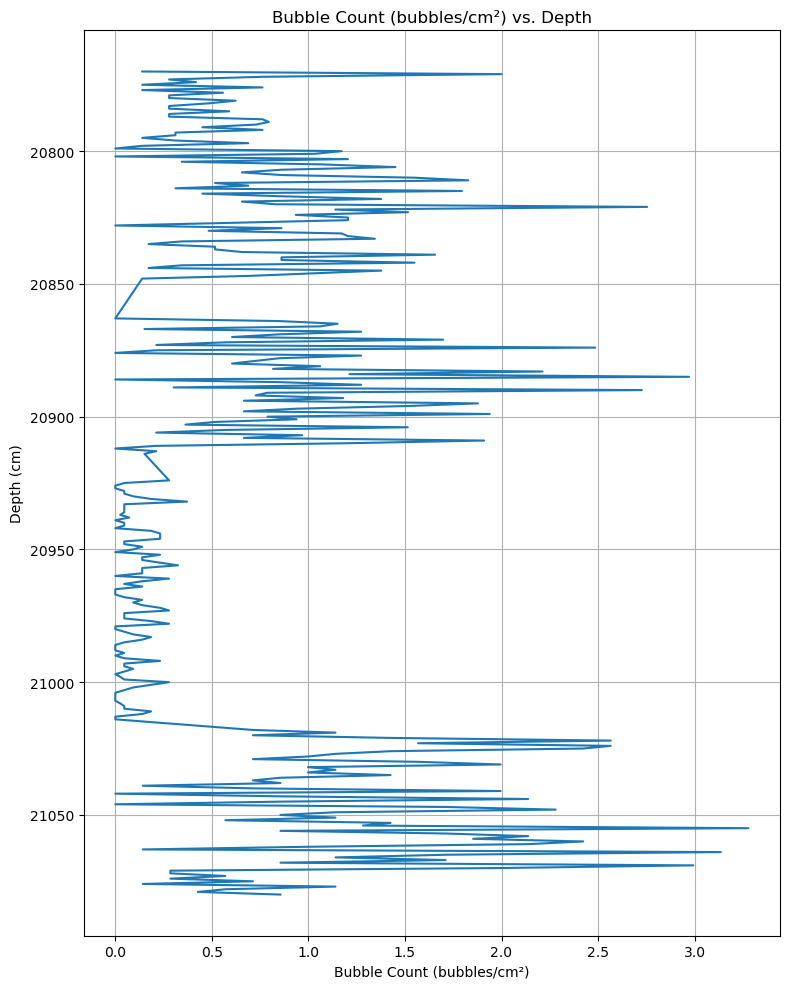


Fixing outliers in 'Avg_Orientation' using rolling median (window=13, threshold=8.0):


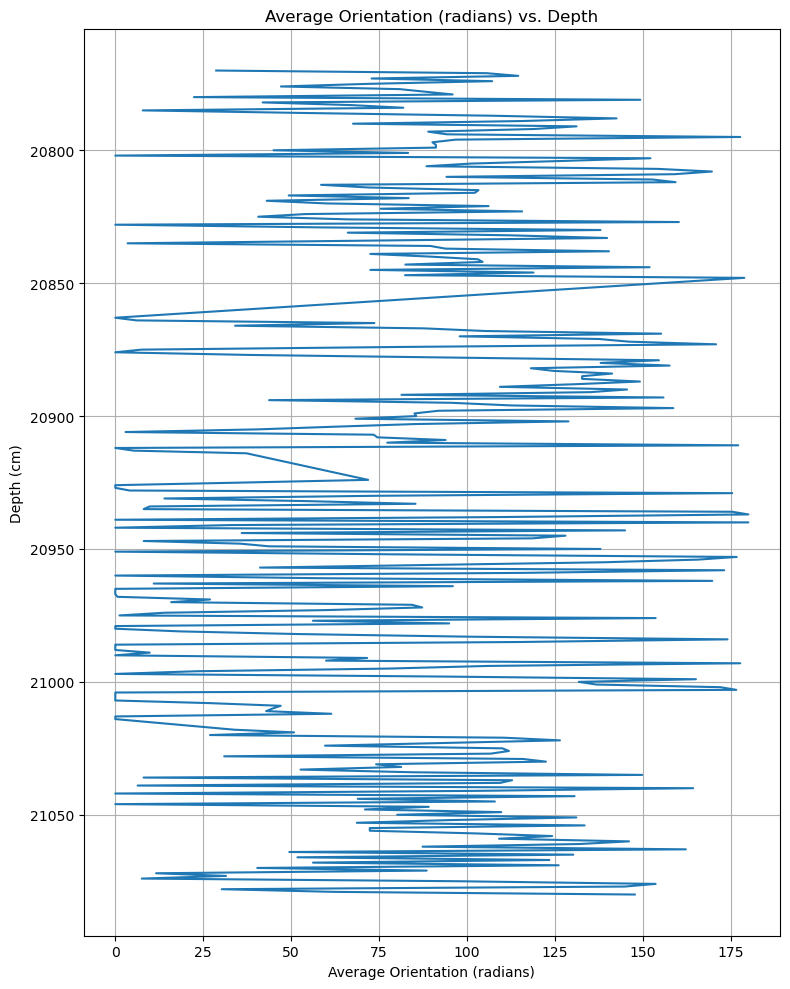


Fixing outliers in 'Avg_Elongation' using rolling median (window=13, threshold=8.0):


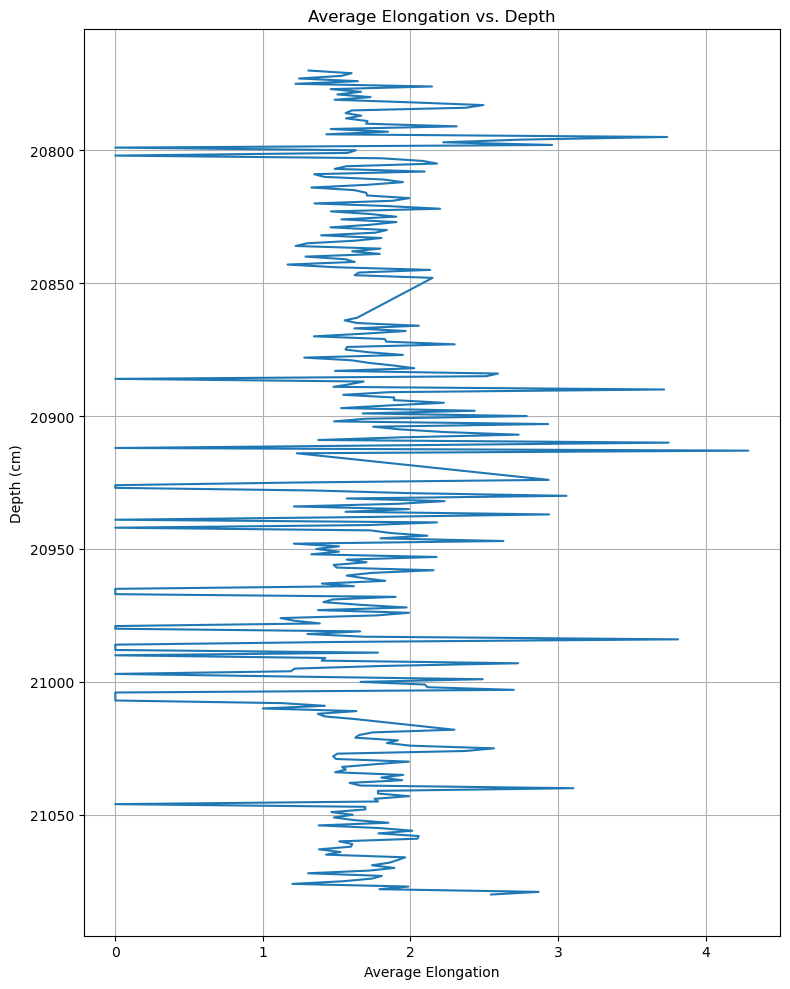

In [5]:
def smooth_outliers_rolling(df: pd.DataFrame, column: str, window: int = 5, threshold: float = 3.0) -> pd.Series:
    series = df[column]
    rolling_median = series.rolling(window=window, center=True).median()
    
    # Calculate deviation from rolling median
    deviation = (series - rolling_median).abs()
    mad = deviation.rolling(window=window, center=True).median()  # Median Absolute Deviation
    
    # Flag outliers: values farther than threshold * MAD from the rolling median
    outliers = deviation > (threshold * mad)
    
    if outliers.any():
        print(f"\nFixing outliers in '{column}' using rolling median (window={window}, threshold={threshold}):")
        #print(df.loc[outliers, ["Depth_cm", column]].to_string(index=False))
    
    # Replace outliers with rolling median values
    fixed_series = series.copy()
    fixed_series[outliers] = rolling_median[outliers]
    
    return fixed_series

file = f"{output_dir}/combinedBubbles.csv"
combined_df = pd.read_csv(file)

# === Define variables to plot ===
plot_vars = [
    ("Normalized_Count", "Bubble Count (bubbles/cm²)"),
    ("Avg_Orientation", "Average Orientation (radians)"),
    ("Avg_Elongation", "Average Elongation")
]

# === Plot each variable vs depth (depth on y-axis) ===
for var, label in plot_vars:
    combined_df[var] = smooth_outliers_rolling(combined_df, var, window=13, threshold=8.0)

    plt.figure(figsize=(8, 10))
    plt.plot(combined_df[var], combined_df["Depth_cm"])

    plt.xlabel(label)
    plt.ylabel("Depth (cm)")
    plt.title(f"{label} vs. Depth")
    plt.gca().invert_yaxis()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

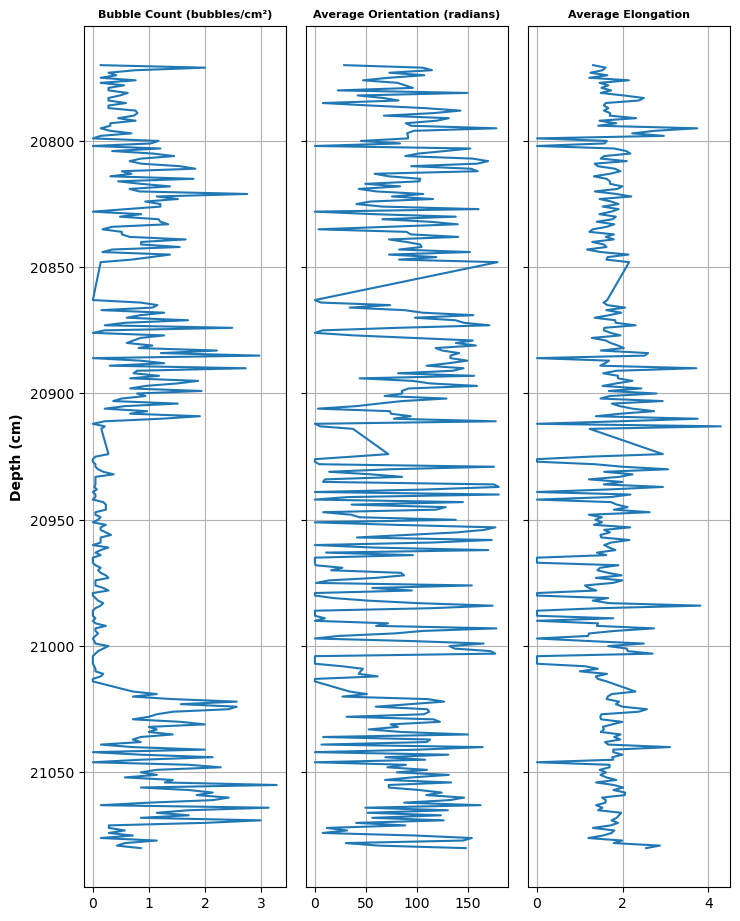

In [9]:
# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.plot(combined_df[var], combined_df["Depth_cm"])
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.show()

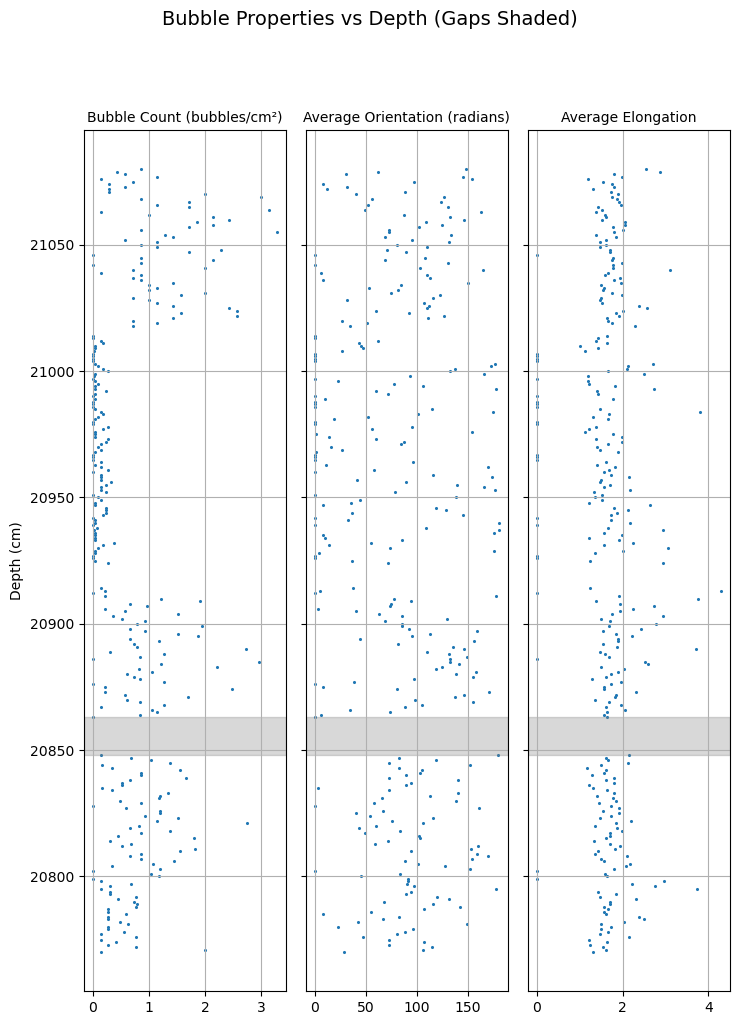

In [7]:
combined_df["Depth_Diff"] = combined_df["Depth_cm"].diff()

gap_threshold = 10
gap_mask = combined_df["Depth_Diff"] > gap_threshold
gap_indices = combined_df.index[gap_mask].tolist()

# --- Get depth ranges for each gap ---
gap_ranges = []
for idx in gap_indices:
    start = combined_df.loc[idx - 1, "Depth_cm"]
    end = combined_df.loc[idx, "Depth_cm"]
    gap_ranges.append((start, end))

# Drop helper column
combined_df = combined_df.drop(columns="Depth_Diff")

# --- Plot the data with gap shading ---
fig, axes = plt.subplots(nrows=1, ncols=len(plot_vars), figsize=(2.5 * len(plot_vars), 10), sharey=True)

for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=10)
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

    # Shade gaps
    for start, end in gap_ranges:
        ax.axhspan(start, end, color='gray', alpha=0.3)

# Add shared y-label
axes[0].set_ylabel("Depth (cm)")

plt.tight_layout()
plt.suptitle("Bubble Properties vs Depth (Gaps Shaded)", y=1.02, fontsize=14)
plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.show()
